# Preparación de los datos

Este notebook busca automatizar el proceso de preparación de datos para prepararlos para modelado.
Se utiliza el dataset de MSWC, incluye la descarga oficial y los métodos de cómo se hizo la preparación.

Nota: 
El dataset tiene un excelente estado inicial, está preparado para que el proyecto esté más enfocado en el desarrollo del modelo que en EDAs o ETLs.
Sin embargo, para poder mejorar el resultado del modelo se me ocurrió añadir ruido a los datos para que el modelo aprenda a funcionar en ambientes con ruido. 

In [1]:
import subprocess
import sys
import tarfile
import zipfile
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

sys.path.insert(0, str(Path.cwd().parent))
from src.audio import load_audio, load_clip, to_int16
from src.config import CLASSES, CLIPS_DIR, PROCESSED_DIR, RAW_DIR, SAMPLE_RATE, SEED, SILENCE, WORDS

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Descarga

El dataset MSWC se divide en dos archivos: una tabla con todos los clips (palabra, speaker y el split oficial) y un archivo grande con audio en Opus formateado en 48 kHz.
Los archivos se guardan en `data/raw/`, si ya existen se saltan para no descargar de nuevo.

In [2]:
URLS = {
    "splits_es.tar.gz": "https://storage.googleapis.com/public-datasets-mswc/splits/es.tar.gz",
    "audio_es.tar.gz": "https://storage.googleapis.com/public-datasets-mswc/audio/es.tar.gz",
    "esc50.zip": "https://github.com/karoldvl/ESC-50/archive/master.zip",
}
RAW_DIR.mkdir(parents=True, exist_ok=True)
for name, url in URLS.items():
    if not (RAW_DIR / name).exists():
        subprocess.run(["curl", "-L", "-o", str(RAW_DIR / name), url], check=True)

if not (RAW_DIR / "es_splits.csv").exists():
    with tarfile.open(RAW_DIR / "splits_es.tar.gz") as tar:
        tar.extractall(RAW_DIR, filter="data")

sorted(path.name for path in RAW_DIR.iterdir())

['audio_es.tar.gz',
 'es_dev.csv',
 'es_splits.csv',
 'es_test.csv',
 'es_train.csv',
 'esc50.zip',
 'splits_es.tar.gz',
 'version.txt']

## Exploración inicial de MSWC

Cada fila es un clip, el speaker es un hash anónimo, lo cual sirve simplemente para saber si la misma persona aparece en más de un split. 

In [3]:
mswc = pd.read_csv(RAW_DIR / "es_splits.csv")
mswc["split"] = mswc["SET"].str.lower()

n_words = mswc["WORD"].nunique(dropna=False)
print(f"{len(mswc):,} clips, {n_words:,} words, {mswc['SPEAKER'].nunique():,} speakers")
display(mswc.head(3))
pd.DataFrame({"clips": mswc["split"].value_counts(), "share": mswc["split"].value_counts(normalize=True).round(3)})

1,208,209 clips, 24,878 words, 12,461 speakers


,SET,LINK,WORD,VALID,SPEAKER,GENDER,split
0,TEST,aang/common_voice_es_19132355.opus,aang,True,8231e4c93d6dd57465894c2dc3edc2423e65b254edb296...,MALE,test
1,DEV,aang/common_voice_es_19590620.opus,aang,True,a97730f86fa90560ae105669364412a9ad393b32839d01...,MALE,dev
2,TRAIN,aang/common_voice_es_19746510.opus,aang,True,b14940e80c81a474bf7f74e3399de142bf6f6cb33319c3...,FEMALE,train


,clips,share
split,,
train,944513,0.782
dev,131850,0.109
test,131846,0.109


Muchas de las palabras tienen muy pocos clips, en este plot se muestra un ranking de cada palabra dependiendo de qué tantos clips tiene, y marca 20 palabras que queremos reconocer.

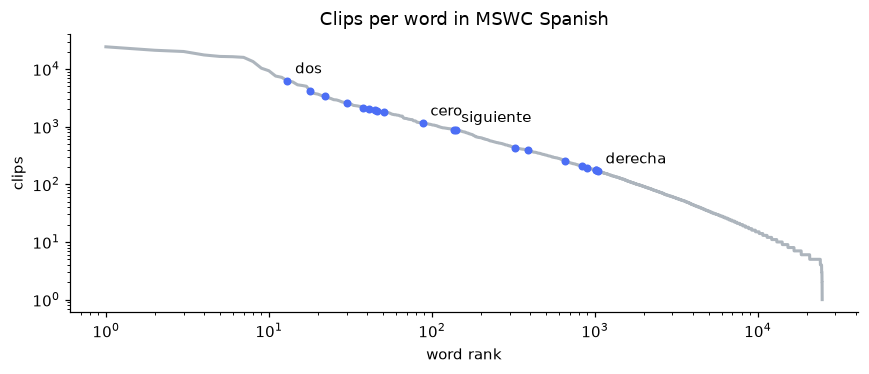

Half of the words have 11 clips or fewer.


In [4]:
per_word = mswc["WORD"].value_counts()
rank = per_word.index.get_indexer(WORDS) + 1

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.loglog(np.arange(1, len(per_word) + 1), per_word.values, color="#ADB5BD", lw=2)
ax.scatter(rank, per_word[WORDS], color="#4C6EF5", zorder=3, s=18)
for word in ["dos", "cero", "siguiente", "derecha"]:
    ax.annotate(word, (per_word.index.get_loc(word) + 1, per_word[word]), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("word rank")
ax.set_ylabel("clips")
ax.set_title("Clips per word in MSWC Spanish")
plt.tight_layout()
plt.show()
print(f"Half of the words have {per_word.median():.0f} clips or fewer.")

## Elección del vocabulario

Los diez dígitos son una elección fácil porque tienen miles de clips. Los diez comandos (siguiente, anterior, música, alto, sigue, adelante, arriba, abajo, izquierda y derecha) sirven para una interfaz de voz y aun así tienen unos cientos de clips cada uno.
"Sí" y "no" también serían buenos comandos, pero MSWC descarta todas las palabras de menos de tres letras, así que no vienen en el dataset.

In [5]:
print("Shortest word in the corpus:", int(mswc["WORD"].str.len().min()), "letters")
print("Is 'sí' in the corpus?", "sí" in per_word.index, "| Is 'no'?", "no" in per_word.index)

ours = mswc[mswc["WORD"].isin(WORDS)]
counts = ours.pivot_table(index="WORD", columns="split", values="LINK", aggfunc="count")
counts = counts.reindex(WORDS)[["train", "dev", "test"]]
counts["total"] = counts.sum(axis=1)
counts

Shortest word in the corpus: 3 letters
Is 'sí' in the corpus? False | Is 'no'? False


split,train,dev,test,total
WORD,,,,
cero,920,115,115,1150
uno,2756,345,345,3446
dos,4967,622,622,6211
tres,3263,408,408,4079
cuatro,2088,262,262,2612
cinco,1510,189,189,1888
seis,1666,209,209,2084
siete,1612,202,202,2016
ocho,1526,191,191,1908


## Selección de clips

Algunos dígitos tienen más de treinta veces los clips de algunos comandos. Para que las clases queden más parejas, cada palabra tiene como máximo 1500 clips de entrenamiento y 200 de dev y de test.

Se agregan dos clases más para llegar a 22:

- `unknown` es cualquier otra palabra, para que el modelo aprenda a rechazar lo que no es un comando.
- `silence` no tiene voz. Aquí estos clips se llenan con ceros y en el entrenamiento se les agrega ruido de fondo.

La idea de añadir estos dos es principalmente util para cuando el modelo escucha en vivo. Como se espera que tenga un stream constante de audio necesita estas dos opciones para detectar el silencio y para detectar palabras que no conoce cuando hay voz presente pero no esta en la pool de comandos.

In [6]:
MAX_TRAIN = 1500
MAX_EVAL = 200
N_UNKNOWN = {"train": 2500, "dev": 300, "test": 300}
N_SILENCE = {"train": 1000, "dev": 150, "test": 150}

rng = np.random.default_rng(SEED)


def new_seed():
    return int(rng.integers(1 << 31))


parts = []
for (split, word), group in ours.groupby(["split", "WORD"]):
    limit = MAX_TRAIN if split == "train" else MAX_EVAL
    chosen = group.sample(n=min(len(group), limit), random_state=new_seed())
    parts.append(chosen.assign(label=word))

others = mswc[~mswc["WORD"].isin(WORDS)]
for split, n in N_UNKNOWN.items():
    group = others[others["split"] == split].sample(frac=1.0, random_state=new_seed())
    group = group.groupby("WORD").head(2)
    chosen = group.sample(n=min(n, len(group)), random_state=new_seed())
    parts.append(chosen.assign(label="unknown"))

selection = pd.concat(parts, ignore_index=True)
selection["y"] = selection["label"].map(CLASSES.index)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
selection.to_csv(PROCESSED_DIR / "selection.csv", index=False)
print(f"{len(selection):,} clips selected (silence clips are added later)")
selection.pivot_table(index="label", columns="split", values="LINK", aggfunc="count").reindex(CLASSES[:-1])[
    ["train", "dev", "test"]]

24,989 clips selected (silence clips are added later)


split,train,dev,test
label,,,
cero,920,115,115
uno,1500,200,200
dos,1500,200,200
tres,1500,200,200
cuatro,1500,200,200
cinco,1500,189,189
seis,1500,200,200
siete,1500,200,200
ocho,1500,191,191


Los splits oficiales no separan a los speakers. Abajo se cuenta cuántos clips de test son de una persona que también tiene clips en nuestro entrenamiento, y si alguna vez es la misma palabra.

In [7]:
train_clips = selection[selection["split"] == "train"]
test_clips = selection[selection["split"] == "test"]
same_speaker = test_clips["SPEAKER"].isin(set(train_clips["SPEAKER"]))
same_speaker_and_word = pd.Series(list(zip(test_clips["SPEAKER"], test_clips["WORD"]))).isin(
    set(zip(train_clips["SPEAKER"], train_clips["WORD"])))

print(f"Test clips whose speaker is also in train: {same_speaker.mean():.1%}")
print(f"Test clips with the same speaker and the same word in train: {same_speaker_and_word.mean():.1%}")

Test clips whose speaker is also in train: 41.3%
Test clips with the same speaker and the same word in train: 0.0%


## Extracción de los clips

El archivo de audio tiene más de un millón de archivos y solo necesitamos unos 25 000. Se lee una sola vez de principio a fin y solo se guardan los clips elegidos en `data/clips/`.

In [8]:
missing = {f"es/clips/{link}" for link in selection["LINK"] if not (CLIPS_DIR / "es" / "clips" / link).exists()}
print(f"{len(missing):,} clips to extract")

if missing:
    with tarfile.open(RAW_DIR / "audio_es.tar.gz", mode="r|gz") as tar:
        for member in tar:
            if member.name in missing:
                path = CLIPS_DIR / member.name
                path.parent.mkdir(parents=True, exist_ok=True)
                path.write_bytes(tar.extractfile(member).read())
                missing.discard(member.name)
                if not missing:
                    break

0 clips to extract


## Escuchar los clips

Los clips ya duran cerca de un segundo, pero el volumen cambia mucho de un speaker a otro. Por eso después, en el entrenamiento, se cambia el volumen de cada clip al azar.

"tres": 1.00 s at 48000 Hz, 1 channel


/Volumes/Taller/projects/tec/comandos-de-voz-es/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


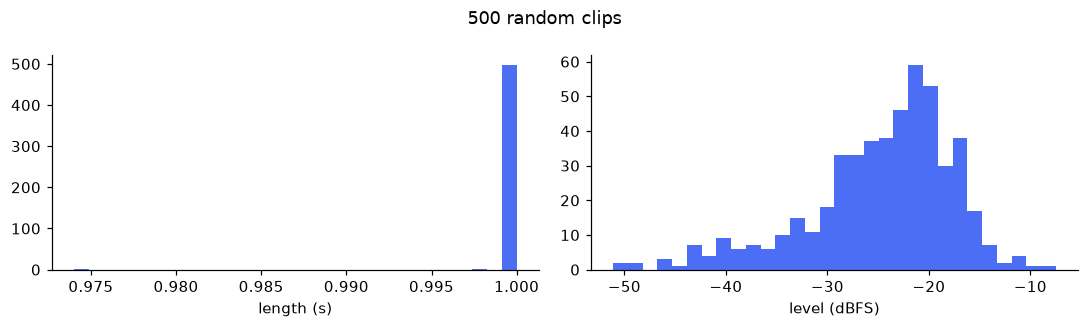

Level from -40 to -16 dBFS (5th to 95th percentile)


In [9]:
def clip_path(link):
    return CLIPS_DIR / "es" / "clips" / link


example = selection[(selection["label"] == "tres") & (selection["split"] == "train")].iloc[0]
info = sf.info(str(clip_path(example["LINK"])))
print(f'"tres": {info.duration:.2f} s at {info.samplerate} Hz, {info.channels} channel')
display(Audio(load_audio(clip_path(example["LINK"])), rate=SAMPLE_RATE))

sample = selection.sample(500, random_state=SEED)
lengths, levels = [], []
for link in sample["LINK"]:
    audio = load_audio(clip_path(link))
    lengths.append(len(audio) / SAMPLE_RATE)
    levels.append(10 * np.log10(np.mean(audio**2) + 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(lengths, bins=30, color="#4C6EF5")
axes[0].set_xlabel("length (s)")
axes[1].hist(levels, bins=30, color="#4C6EF5")
axes[1].set_xlabel("level (dBFS)")
fig.suptitle("500 random clips")
plt.tight_layout()
plt.show()
print(f"Level from {np.percentile(levels, 5):.0f} to {np.percentile(levels, 95):.0f} dBFS (5th to 95th percentile)")

## Conversión a 16 kHz

Cada clip se remuestrea a 16 kHz, se recorta o se rellena para que dure exactamente un segundo y se guarda como enteros de 16 bits. Los clips de silencio se agregan al final de cada split.

In [10]:
def save_split(split):
    group = selection[selection["split"] == split].reset_index(drop=True)
    paths = [clip_path(link) for link in group["LINK"]]
    with ProcessPoolExecutor() as pool:
        audio = list(pool.map(load_clip, paths, chunksize=64))

    n_silence = N_SILENCE[split]
    x = np.concatenate([np.stack(audio), np.zeros((n_silence, SAMPLE_RATE), np.int16)])
    y = np.concatenate([group["y"].to_numpy(), np.full(n_silence, SILENCE)])
    word = np.concatenate([group["WORD"].to_numpy(), np.full(n_silence, "silence")]).astype(str)
    np.savez(PROCESSED_DIR / f"{split}.npz", x=x, y=y.astype(np.int64), word=word)
    return len(y)


for split in ["train", "dev", "test"]:
    print(f"{split}: {save_split(split):,} clips")

train: 20,875 clips


dev: 2,707 clips


test: 2,707 clips


## Ruido de fondo

ESC-50 tiene 50 tipos de sonido con 40 grabaciones cada uno, ya divididos en cinco folds. Los folds 1 a 3 son para entrenar, el 4 para validación y el 5 para test, así el ruido del test es nuevo para el modelo.

In [11]:
esc50 = RAW_DIR / "ESC-50-master"
if not esc50.exists():
    with zipfile.ZipFile(RAW_DIR / "esc50.zip") as archive:
        archive.extractall(RAW_DIR)

meta = pd.read_csv(esc50 / "meta" / "esc50.csv")
print(f"{len(meta)} recordings, {meta['category'].nunique()} categories, folds {sorted(meta['fold'].unique().tolist())}")
print("Some categories:", ", ".join(meta["category"].drop_duplicates().sample(8, random_state=SEED)))

FOLDS = {"train": [1, 2, 3], "dev": [4], "test": [5]}
noise = {}
for split, folds in FOLDS.items():
    paths = [esc50 / "audio" / name for name in meta[meta["fold"].isin(folds)]["filename"]]
    with ProcessPoolExecutor() as pool:
        audio = list(pool.map(load_audio, paths, chunksize=16))
    audio = [a for a in audio if np.sqrt(np.mean(a**2)) > 1e-3]
    length = min(len(a) for a in audio)
    noise[split] = np.stack([a[:length] for a in audio])
    print(f"{split}: {len(audio)} recordings of {length / SAMPLE_RATE:.1f} s")

np.savez(PROCESSED_DIR / "noise.npz", **{split: to_int16(audio) for split, audio in noise.items()})

2000 recordings, 50 categories, folds [1, 2, 3, 4, 5]
Some categories: rain, mouse_click, airplane, washing_machine, vacuum_cleaner, drinking_sipping, snoring, hen


train: 1199 recordings of 5.0 s


dev: 400 recordings of 5.0 s


test: 400 recordings of 5.0 s


Algunas grabaciones de ESC-50 son un sonido corto seguido de silencio digital. Si en el entrenamiento se tomara un segundo al azar de esas grabaciones, una mezcla que debería estar a 0 dB podría quedar sin nada de ruido. El plot muestra qué tanto del ruido es silencio.

1 s windows below -60 dBFS: 10.8%


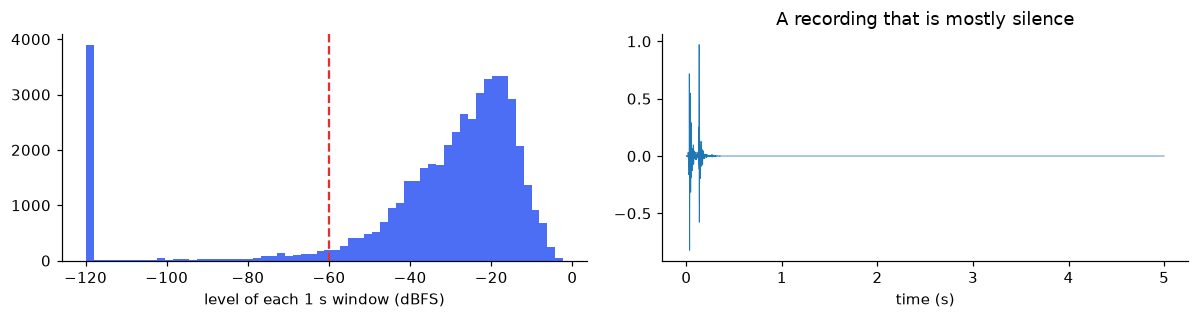

In [12]:
def window_levels(audio, hop=SAMPLE_RATE // 10):
    starts = np.arange(0, audio.shape[1] - SAMPLE_RATE + 1, hop)
    return np.stack([10 * np.log10(np.mean(audio[:, s:s + SAMPLE_RATE] ** 2, axis=1) + 1e-12) for s in starts], axis=1)


levels = window_levels(noise["train"])
print(f"1 s windows below -60 dBFS: {np.mean(levels < -60):.1%}")

quiet = int(np.argmax((levels < -60).mean(axis=1)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(levels.ravel(), bins=60, color="#4C6EF5")
axes[0].axvline(-60, color="#E03131", ls="--")
axes[0].set_xlabel("level of each 1 s window (dBFS)")
axes[1].plot(np.arange(noise["train"].shape[1]) / SAMPLE_RATE, noise["train"][quiet], lw=0.5)
axes[1].set_xlabel("time (s)")
axes[1].set_title("A recording that is mostly silence")
plt.tight_layout()
plt.show()

## Resultado

`data/processed/` ya tiene todo lo que necesita el notebook del modelo:

| Archivo | Contenido |
|---|---|
| `train.npz`, `dev.npz`, `test.npz` | `x` audio (int16, 1 s a 16 kHz), `y` índice de la clase, `word` la palabra que se dice |
| `noise.npz` | Ruido de ESC-50 a 16 kHz para `train`, `dev` y `test` |
| `selection.csv` | Qué clip de MSWC quedó en qué split y en qué clase |

In [13]:
for path in sorted(PROCESSED_DIR.iterdir()):
    print(f"{path.name:<15} {path.stat().st_size / 1e6:7.1f} MB")

dev.npz            86.8 MB
noise.npz         319.8 MB
selection.csv       5.0 MB
test.npz           86.8 MB
train.npz         669.5 MB
